ZEROQ AI - NOTEBOOK 07: FEATURE ENGINEERING
Project folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training
Processed data folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\processed_data
Feature output folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data

Dataset dimensions:
Production Batches: (24000, 20)
Complaints: (6000, 14)
Quality Inspections: (37245, 11)
Products: (20, 6)
Facilities: (5, 4)
Production Lines: (15, 6)
Materials: (40, 6)

Identified columns:
Batch ID: batch_id
Product ID: product_id
Facility ID: facility_id
Production Line ID: production_line_id
Production Date: production_date
Dispatch Date: planned_dispatch_date
Complaint Batch ID: batch_id
Complaint Date: complaint_date
Inspection Date: inspection_date

Prediction date availability:
prediction_date_source
dispatch_date    24000
Name: count, dtype: int64

Target distribution:
complaint_within_90_days
0    18928
1     5072
Name: count, dtype: int64

Target 

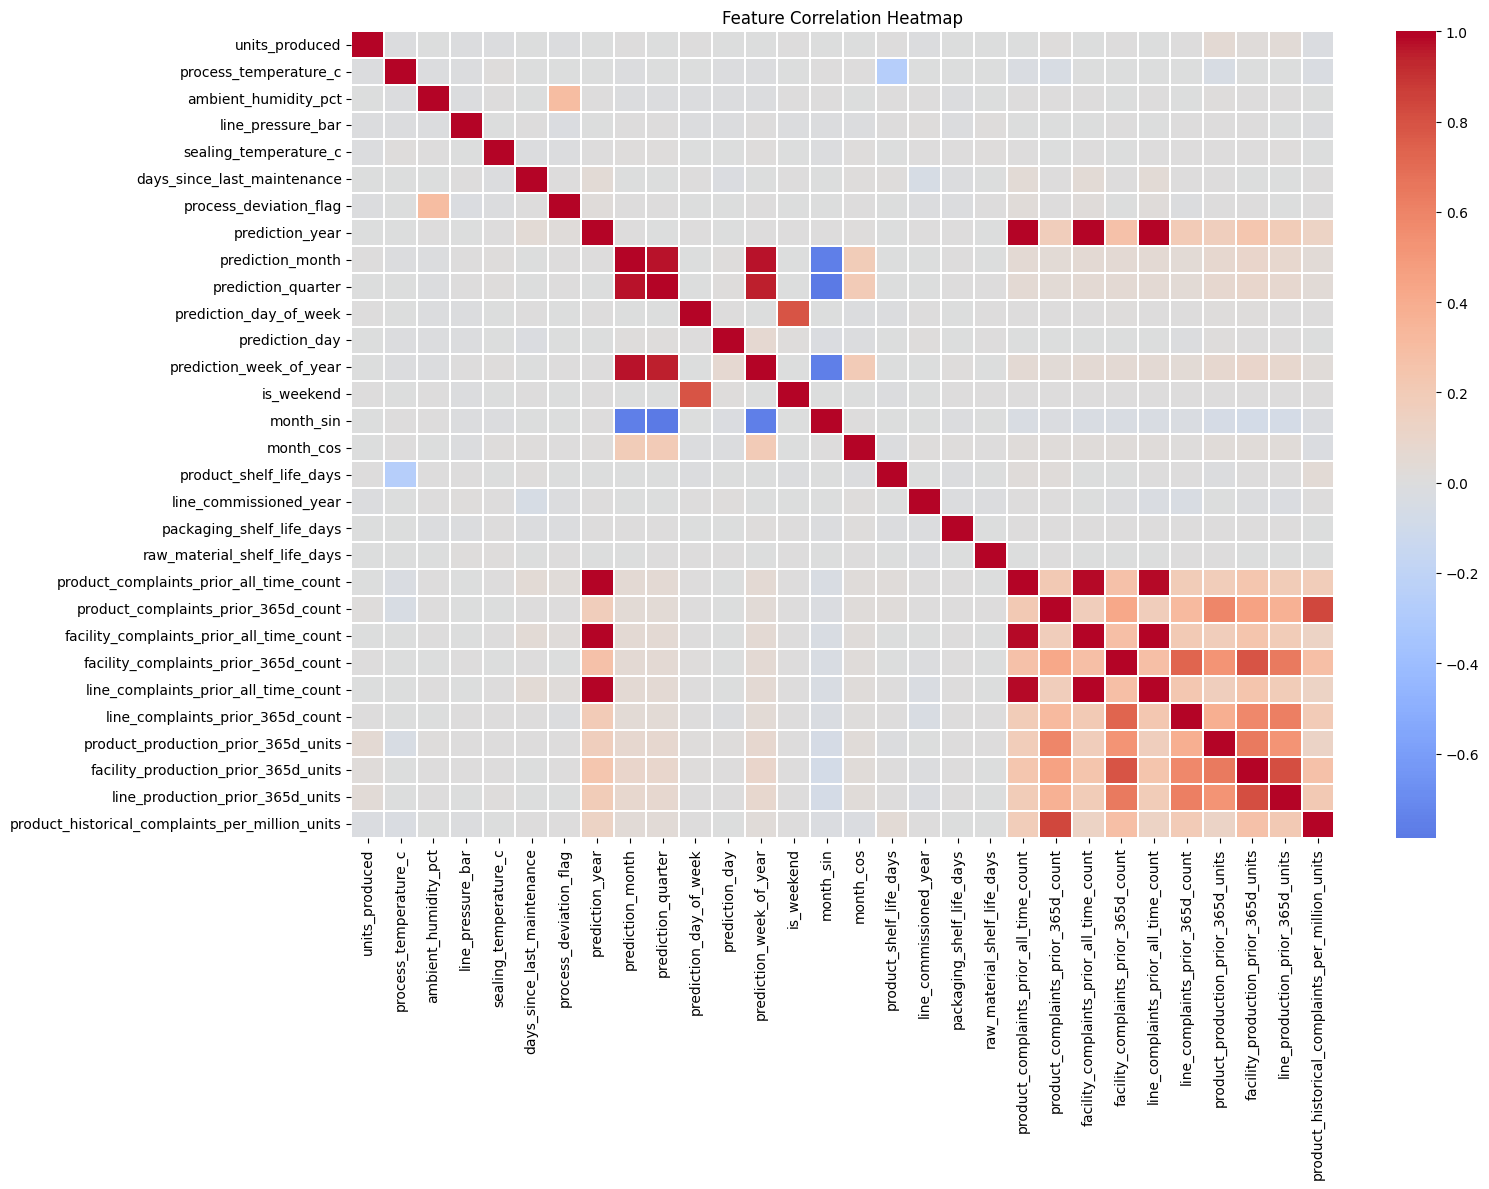

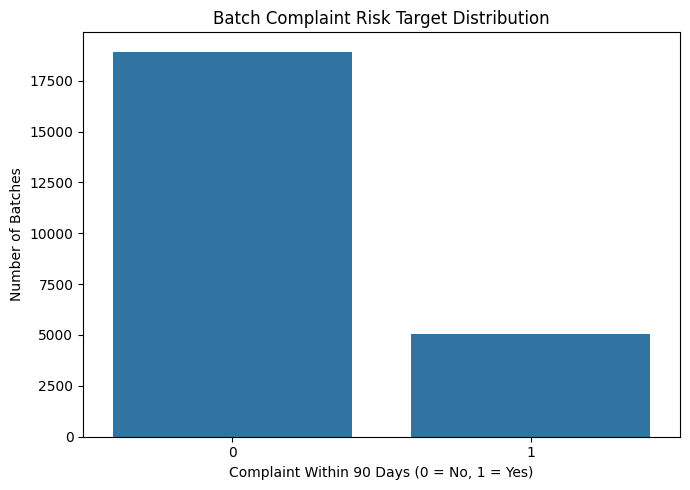


Historical complaint feature summary:


,Feature,count,mean,std,min,25%,50%,75%,max
0,product_complaints_prior_365d_count,24000.0,15.372917,4.714838,0.0,13.0,16.0,18.0,31.0
1,facility_complaints_prior_365d_count,24000.0,61.558167,12.385445,0.0,57.0,63.0,68.0,91.0
2,line_complaints_prior_365d_count,24000.0,20.530125,5.636318,0.0,17.0,21.0,24.0,42.0



Saved datasets:
d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data\batch_features_pre_dispatch.csv
d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data\batch_model_features.csv
d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data\batch_complaint_target.csv

Feature engineering report saved.

FEATURE ENGINEERING COMPLETED
Total batches: 24000
Total engineered columns: 71
Model feature count: 67
Batches with complaint within 90 days: 5072
Batches without complaint within 90 days: 18928

Output files:
1. batch_features_pre_dispatch.csv
2. batch_model_features.csv
3. batch_complaint_target.csv
4. feature_engineering_report.xlsx

Output folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data

IMPORTANT:
1. Do not use target columns as model inputs.
2. Do not use investigation or corrective-action fields for pre-dispatch prediction.
3. Fit encoders, imputers and scalers on trai

In [1]:

# ============================================================
# NOTEBOOK 07: FEATURE ENGINEERING
# Project: ZeroQ AI - Predictive Quality Intelligence System
# Objective: Create leakage-safe, pre-dispatch batch features
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("=" * 80)
print("ZEROQ AI - NOTEBOOK 07: FEATURE ENGINEERING")
print("=" * 80)


# ============================================================
# 1. AUTOMATICALLY LOCATE PROJECT FOLDERS
# ============================================================

DATASET_FILES = [
    "products_cleaned.csv",
    "customers_cleaned.csv",
    "facilities_cleaned.csv",
    "production_lines_cleaned.csv",
    "materials_cleaned.csv",
    "production_batches_cleaned.csv",
    "complaints_cleaned.csv",
    "quality_inspections_cleaned.csv",
    "investigations_cleaned.csv",
    "corrective_actions_cleaned.csv",
    "data_dictionary_cleaned.csv"
]

search_roots = [Path.cwd()] + list(Path.cwd().parents)
BASE_PATH = None

for root in search_roots:
    for candidate in root.rglob("processed_data"):
        if all((candidate / file).exists() for file in DATASET_FILES):
            BASE_PATH = candidate
            break
    if BASE_PATH is not None:
        break

if BASE_PATH is None:
    raise FileNotFoundError(
        "Could not locate processed_data containing all 11 cleaned CSV files.\n"
        f"Current working directory: {Path.cwd()}\n"
        "Check that Notebook 2 completed successfully and all cleaned CSVs exist."
    )

PROJECT_PATH = BASE_PATH.parent

FEATURE_PATH = PROJECT_PATH / "feature_engineered_data"
REPORT_PATH = PROJECT_PATH / "preprocessing" / "reports"
VISUALIZATION_PATH = PROJECT_PATH / "visualizations" / "feature_engineering"

FEATURE_PATH.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)
VISUALIZATION_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_PATH)
print("Processed data folder:", BASE_PATH)
print("Feature output folder:", FEATURE_PATH)


# ============================================================
# 2. LOAD REQUIRED DATASETS
# ============================================================

def load_dataset(name):
    path = BASE_PATH / f"{name}_cleaned.csv"

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()

    return df


batches = load_dataset("production_batches")
complaints = load_dataset("complaints")
inspections = load_dataset("quality_inspections")
products = load_dataset("products")
facilities = load_dataset("facilities")
production_lines = load_dataset("production_lines")
materials = load_dataset("materials")

print("\nDataset dimensions:")
for name, df in {
    "Production Batches": batches,
    "Complaints": complaints,
    "Quality Inspections": inspections,
    "Products": products,
    "Facilities": facilities,
    "Production Lines": production_lines,
    "Materials": materials
}.items():
    print(f"{name}: {df.shape}")


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def find_column(df, candidates, contains=None):
    """
    Find a column using exact candidate names first,
    then optional keyword matching.
    """
    lower_map = {col.lower().strip(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    if contains:
        for keyword in contains:
            for col in df.columns:
                if keyword.lower() in col.lower():
                    return col

    return None


def parse_date_column(df, column):
    if column and column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")
    return df


def safe_numeric(df, columns):
    for col in columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def unique_dimension(df, key):
    """
    Prevent row multiplication when joining dimension tables.
    Keep the first record for duplicated dimension keys.
    Duplicates are reported separately.
    """
    if key is None or key not in df.columns:
        return df.copy()

    return df.drop_duplicates(subset=[key], keep="first").copy()


# ============================================================
# 4. IDENTIFY IMPORTANT COLUMNS
# ============================================================

batch_id = find_column(
    batches,
    ["batch_id", "production_batch_id"]
)

product_id = find_column(
    batches,
    ["product_id"]
)

facility_id = find_column(
    batches,
    ["facility_id", "plant_id"]
)

line_id = find_column(
    batches,
    ["production_line_id", "line_id"]
)

batch_date = find_column(
    batches,
    [
        "production_date",
        "batch_date",
        "manufacturing_date",
        "production_start_date",
        "manufacturing_datetime"
    ],
    contains=["production_date", "manufacturing_date"]
)

dispatch_date = find_column(
    batches,
    [
        "dispatch_date",
        "dispatch_datetime",
        "shipment_date",
        "shipped_at",
        "dispatch_at"
    ],
    contains=["dispatch_date", "shipment_date", "shipped_at"]
)

complaint_id = find_column(
    complaints,
    ["complaint_id", "customer_complaint_id"]
)

complaint_batch_id = find_column(
    complaints,
    ["batch_id", "production_batch_id"]
)

complaint_product_id = find_column(
    complaints,
    ["product_id"]
)

complaint_date = find_column(
    complaints,
    [
        "complaint_date",
        "date_received",
        "received_date",
        "reported_date",
        "created_at"
    ],
    contains=["complaint_date", "received_date", "reported_date"]
)

inspection_batch_id = find_column(
    inspections,
    ["batch_id", "production_batch_id"]
)

inspection_date = find_column(
    inspections,
    [
        "inspection_date",
        "inspection_datetime",
        "tested_at",
        "created_at"
    ],
    contains=["inspection_date", "tested_at"]
)

print("\nIdentified columns:")
for name, col in {
    "Batch ID": batch_id,
    "Product ID": product_id,
    "Facility ID": facility_id,
    "Production Line ID": line_id,
    "Production Date": batch_date,
    "Dispatch Date": dispatch_date,
    "Complaint Batch ID": complaint_batch_id,
    "Complaint Date": complaint_date,
    "Inspection Date": inspection_date
}.items():
    print(f"{name}: {col}")

if batch_id is None:
    raise ValueError("Could not identify batch_id in production_batches.")

if batch_date is None:
    raise ValueError(
        "Could not identify a production date column. "
        "Check the production_batches.csv column names."
    )

if complaint_batch_id is None:
    raise ValueError(
        "Could not identify batch_id in complaints. "
        "A batch-level complaint target cannot be created."
    )

if complaint_date is None:
    raise ValueError(
        "Could not identify complaint_date. "
        "A time-aware target cannot be created safely."
    )


# ============================================================
# 5. PREPARE DATE COLUMNS
# ============================================================

batches = parse_date_column(batches, batch_date)

if dispatch_date:
    batches = parse_date_column(batches, dispatch_date)

complaints = parse_date_column(complaints, complaint_date)

if inspection_date:
    inspections = parse_date_column(inspections, inspection_date)

# Use dispatch date when available.
# Otherwise, use production date as a fallback.
if dispatch_date:
    batches["prediction_date"] = batches[dispatch_date].fillna(
        batches[batch_date]
    )
else:
    batches["prediction_date"] = batches[batch_date]

batches["prediction_date_source"] = np.where(
    batches["prediction_date"].notna(),
    "dispatch_date" if dispatch_date else "production_date",
    "missing"
)

batches = batches.dropna(subset=["prediction_date"]).copy()

print("\nPrediction date availability:")
print(batches["prediction_date_source"].value_counts(dropna=False))


# ============================================================
# 6. CREATE BATCH-LEVEL TARGET
# ============================================================

# Target definition:
# 1 = At least one complaint linked to the batch within
#     90 days after its prediction date.
# 0 = No such complaint found in the observation window.
#
# This target is an outcome label, NOT a model feature.

COMPLAINT_HORIZON_DAYS = 90

target_complaints = complaints[
    [complaint_batch_id, complaint_date]
].copy()

target_complaints = target_complaints.dropna(
    subset=[complaint_batch_id, complaint_date]
)

target_complaints = target_complaints.rename(
    columns={
        complaint_batch_id: "batch_id_target",
        complaint_date: "complaint_date_target"
    }
)

target_batches = batches[
    [batch_id, "prediction_date"]
].copy()

target_batches = target_batches.rename(
    columns={batch_id: "batch_id_target"}
)

target_complaints = target_complaints.merge(
    target_batches,
    on="batch_id_target",
    how="inner"
)

target_complaints["days_after_prediction"] = (
    target_complaints["complaint_date_target"]
    - target_complaints["prediction_date"]
).dt.days

valid_target_complaints = target_complaints[
    (
        target_complaints["days_after_prediction"] >= 0
    )
    &
    (
        target_complaints["days_after_prediction"]
        <= COMPLAINT_HORIZON_DAYS
    )
].copy()

target_counts = (
    valid_target_complaints
    .groupby("batch_id_target")
    .size()
    .rename("target_complaint_count")
)

feature_df = batches.copy()

feature_df["complaint_within_90_days"] = (
    feature_df[batch_id]
    .map(target_counts)
    .fillna(0)
    .gt(0)
    .astype(int)
)

feature_df["target_complaint_count"] = (
    feature_df[batch_id]
    .map(target_counts)
    .fillna(0)
    .astype(int)
)

print("\nTarget distribution:")
print(feature_df["complaint_within_90_days"].value_counts())

print("\nTarget percentage:")
print(
    feature_df["complaint_within_90_days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ============================================================
# 7. DATE-BASED FEATURES
# ============================================================

feature_df["prediction_year"] = (
    feature_df["prediction_date"].dt.year
)

feature_df["prediction_month"] = (
    feature_df["prediction_date"].dt.month
)

feature_df["prediction_quarter"] = (
    feature_df["prediction_date"].dt.quarter
)

feature_df["prediction_day_of_week"] = (
    feature_df["prediction_date"].dt.dayofweek
)

feature_df["prediction_day"] = (
    feature_df["prediction_date"].dt.day
)

feature_df["prediction_week_of_year"] = (
    feature_df["prediction_date"].dt.isocalendar().week.astype("float")
)

feature_df["is_weekend"] = (
    feature_df["prediction_day_of_week"] >= 5
).astype(int)

# Cyclical encoding for month
feature_df["month_sin"] = np.sin(
    2 * np.pi * feature_df["prediction_month"] / 12
)

feature_df["month_cos"] = np.cos(
    2 * np.pi * feature_df["prediction_month"] / 12
)


# ============================================================
# 8. JOIN PRODUCT, FACILITY AND PRODUCTION LINE FEATURES
# ============================================================

# Product information
if product_id and "product_id" in products.columns:
    product_dim = unique_dimension(products, "product_id")

    product_features = [
        col for col in product_dim.columns
        if col != "product_id"
        and not col.lower().endswith("_id")
    ]

    product_dim = product_dim[
        ["product_id"] + product_features
    ]

    product_dim = product_dim.rename(
        columns={
            col: f"product_{col}"
            for col in product_features
        }
    )

    feature_df = feature_df.merge(
        product_dim,
        on=product_id,
        how="left"
    )


# Facility information
if facility_id and "facility_id" in facilities.columns:
    facility_dim = unique_dimension(facilities, "facility_id")

    facility_features = [
        col for col in facility_dim.columns
        if col != "facility_id"
        and not col.lower().endswith("_id")
    ]

    facility_dim = facility_dim[
        ["facility_id"] + facility_features
    ]

    facility_dim = facility_dim.rename(
        columns={
            col: f"facility_{col}"
            for col in facility_features
        }
    )

    feature_df = feature_df.merge(
        facility_dim,
        on=facility_id,
        how="left"
    )


# Production line information
if line_id and "production_line_id" in production_lines.columns:
    line_dim = unique_dimension(
        production_lines,
        "production_line_id"
    )

    line_features = [
        col for col in line_dim.columns
        if col != "production_line_id"
        and not col.lower().endswith("_id")
    ]

    line_dim = line_dim[
        ["production_line_id"] + line_features
    ]

    line_dim = line_dim.rename(
        columns={
            col: f"line_{col}"
            for col in line_features
        }
    )

    feature_df = feature_df.merge(
        line_dim,
        on=line_id,
        how="left"
    )


# ============================================================
# 9. JOIN RAW MATERIAL AND PACKAGING MATERIAL FEATURES
# ============================================================

packaging_material_id = find_column(
    feature_df,
    ["packaging_material_id"]
)

raw_material_id = find_column(
    feature_df,
    ["raw_material_id"]
)

material_key = find_column(
    materials,
    ["material_id"]
)

if material_key:

    material_dim = unique_dimension(
        materials,
        material_key
    )

    material_features = [
        col for col in material_dim.columns
        if col != material_key
        and not col.lower().endswith("_id")
    ]

    if packaging_material_id:
        packaging_dim = material_dim[
            [material_key] + material_features
        ].copy()

        packaging_dim = packaging_dim.rename(
            columns={
                col: f"packaging_{col}"
                for col in material_features
            }
        )

        packaging_dim = packaging_dim.rename(
            columns={material_key: packaging_material_id}
        )

        feature_df = feature_df.merge(
            packaging_dim,
            on=packaging_material_id,
            how="left"
        )

    if raw_material_id:
        raw_dim = material_dim[
            [material_key] + material_features
        ].copy()

        raw_dim = raw_dim.rename(
            columns={
                col: f"raw_material_{col}"
                for col in material_features
            }
        )

        raw_dim = raw_dim.rename(
            columns={material_key: raw_material_id}
        )

        feature_df = feature_df.merge(
            raw_dim,
            on=raw_material_id,
            how="left"
        )


# ============================================================
# 10. HISTORICAL COMPLAINT FEATURES
# ============================================================

# Complaint records are connected to production batches.
# Historical features are calculated only from complaints
# whose dates are strictly earlier than the prediction date.

historical_events = complaints[
    [complaint_batch_id, complaint_date]
].copy()

historical_events = historical_events.rename(
    columns={
        complaint_batch_id: "batch_id",
        complaint_date: "historical_complaint_date"
    }
)

historical_events = historical_events.dropna(
    subset=["batch_id", "historical_complaint_date"]
)

# Attach product, facility and line information to historical complaints.
batch_metadata_columns = [batch_id]

for col in [product_id, facility_id, line_id]:
    if col and col not in batch_metadata_columns:
        batch_metadata_columns.append(col)

batch_metadata = batches[
    batch_metadata_columns
].drop_duplicates(subset=[batch_id])

batch_metadata = batch_metadata.rename(
    columns={batch_id: "batch_id"}
)

historical_events = historical_events.merge(
    batch_metadata,
    on="batch_id",
    how="left"
)


def add_historical_counts(
    base_df,
    events_df,
    group_column,
    event_date_column,
    prefix,
    window_days=365
):
    """
    Calculate prior all-time and prior rolling-window event counts.

    Events on the prediction date are excluded.
    Only events strictly before prediction_date are counted.
    """

    all_time_col = f"{prefix}_prior_all_time_count"
    rolling_col = f"{prefix}_prior_{window_days}d_count"

    base_df[all_time_col] = 0
    base_df[rolling_col] = 0

    if group_column is None or group_column not in base_df.columns:
        return base_df

    if group_column not in events_df.columns:
        return base_df

    valid_events = events_df[
        [group_column, event_date_column]
    ].dropna().copy()

    valid_events[event_date_column] = pd.to_datetime(
        valid_events[event_date_column],
        errors="coerce"
    )

    valid_events = valid_events.dropna(
        subset=[event_date_column]
    )

    valid_events = valid_events.sort_values(event_date_column)

    for group_value, row_indices in base_df.groupby(
        group_column,
        dropna=True
    ).groups.items():

        group_events = valid_events[
            valid_events[group_column] == group_value
        ]

        if group_events.empty:
            continue

        event_dates = (
            group_events[event_date_column]
            .sort_values()
            .values
            .astype("datetime64[ns]")
        )

        prediction_dates = (
            base_df.loc[row_indices, "prediction_date"]
            .values
            .astype("datetime64[ns]")
        )

        # Number of events strictly before prediction date
        previous_count = np.searchsorted(
            event_dates,
            prediction_dates,
            side="left"
        )

        rolling_start = (
            prediction_dates
            - np.timedelta64(window_days, "D")
        )

        previous_window_start = np.searchsorted(
            event_dates,
            rolling_start,
            side="left"
        )

        base_df.loc[row_indices, all_time_col] = previous_count

        base_df.loc[row_indices, rolling_col] = (
            previous_count - previous_window_start
        )

    return base_df


# Product-level historical complaint features
if product_id and product_id in feature_df.columns:
    feature_df = add_historical_counts(
        feature_df,
        historical_events,
        product_id,
        "historical_complaint_date",
        "product_complaints"
    )

# Facility-level historical complaint features
if facility_id and facility_id in feature_df.columns:
    feature_df = add_historical_counts(
        feature_df,
        historical_events,
        facility_id,
        "historical_complaint_date",
        "facility_complaints"
    )

# Production-line historical complaint features
if line_id and line_id in feature_df.columns:
    feature_df = add_historical_counts(
        feature_df,
        historical_events,
        line_id,
        "historical_complaint_date",
        "line_complaints"
    )

print("\nHistorical complaint features generated.")


# ============================================================
# 11. HISTORICAL PRODUCTION VOLUME FEATURES
# ============================================================

units_column = find_column(
    batches,
    [
        "units_produced",
        "quantity_produced",
        "production_quantity",
        "total_units"
    ],
    contains=["units_produced", "quantity_produced"]
)

if units_column:
    batches[units_column] = pd.to_numeric(
        batches[units_column],
        errors="coerce"
    )

    # Create a reusable function for historical production volume.
    def add_historical_volume(
        base_df,
        source_df,
        group_column,
        date_column,
        quantity_column,
        prefix,
        window_days=365
    ):
        output_col = f"{prefix}_prior_{window_days}d_units"

        base_df[output_col] = 0.0

        if group_column is None:
            return base_df

        if group_column not in source_df.columns:
            return base_df

        valid = source_df[
            [group_column, date_column, quantity_column]
        ].copy()

        valid[quantity_column] = pd.to_numeric(
            valid[quantity_column],
            errors="coerce"
        )

        valid = valid.dropna(
            subset=[group_column, date_column, quantity_column]
        )

        for group_value, row_indices in base_df.groupby(
            group_column,
            dropna=True
        ).groups.items():

            group_data = valid[
                valid[group_column] == group_value
            ].sort_values(date_column)

            if group_data.empty:
                continue

            dates = group_data[date_column].values.astype(
                "datetime64[ns]"
            )

            quantities = group_data[quantity_column].values.astype(float)

            cumulative = np.concatenate(
                [[0.0], np.cumsum(quantities)]
            )

            prediction_dates = base_df.loc[
                row_indices, "prediction_date"
            ].values.astype("datetime64[ns]")

            end_positions = np.searchsorted(
                dates,
                prediction_dates,
                side="left"
            )

            start_positions = np.searchsorted(
                dates,
                prediction_dates - np.timedelta64(window_days, "D"),
                side="left"
            )

            volume = (
                cumulative[end_positions]
                - cumulative[start_positions]
            )

            base_df.loc[row_indices, output_col] = volume

        return base_df

    production_history = batches.copy()

    production_history["prediction_date"] = production_history[
        batch_date
    ]

    feature_df = add_historical_volume(
        feature_df,
        production_history,
        product_id,
        batch_date,
        units_column,
        "product_production"
    )

    if facility_id:
        feature_df = add_historical_volume(
            feature_df,
            production_history,
            facility_id,
            batch_date,
            units_column,
            "facility_production"
        )

    if line_id:
        feature_df = add_historical_volume(
            feature_df,
            production_history,
            line_id,
            batch_date,
            units_column,
            "line_production"
        )

    # Historical complaint rate per million units.
    for prefix in [
        "product",
        "facility",
        "line"
    ]:
        complaint_col = (
            f"{prefix}_complaints_prior_365d_count"
        )

        volume_col = (
            f"{prefix}_production_prior_365d_units"
        )

        if complaint_col in feature_df.columns and volume_col in feature_df.columns:
            feature_df[
                f"{prefix}_historical_complaints_per_million_units"
            ] = np.where(
                feature_df[volume_col] > 0,
                (
                    feature_df[complaint_col]
                    / feature_df[volume_col]
                ) * 1_000_000,
                np.nan
            )

print("Historical production volume features generated.")


# ============================================================
# 12. QUALITY INSPECTION FEATURES
# ============================================================

if inspection_batch_id and inspection_date:

    inspection_data = inspections.copy()

    inspection_data = parse_date_column(
        inspection_data,
        inspection_date
    )

    # Keep only inspections completed on or before prediction date.
    inspection_join = inspection_data.merge(
        feature_df[[batch_id, "prediction_date"]].rename(
            columns={batch_id: "batch_id"}
        ),
        left_on=inspection_batch_id,
        right_on="batch_id",
        how="inner"
    )

    inspection_join = inspection_join[
        inspection_join[inspection_date]
        <= inspection_join["prediction_date"]
    ].copy()

    inspection_join = inspection_join.drop(
        columns=["prediction_date"],
        errors="ignore"
    )

    inspection_status = find_column(
        inspection_join,
        [
            "inspection_status",
            "inspection_result",
            "quality_status",
            "result",
            "status"
        ]
    )

    inspection_value_columns = []

    for col in inspection_join.select_dtypes(
        include=np.number
    ).columns:

        if col.lower().endswith("_id"):
            continue

        if col == "batch_id":
            continue

        inspection_value_columns.append(col)

    aggregation = {}

    aggregation["inspection_record_count"] = (
        inspection_batch_id,
        "count"
    )

    if inspection_status:
        inspection_join["_inspection_pass_flag"] = (
            inspection_join[inspection_status]
            .astype(str)
            .str.lower()
            .str.contains(
                r"pass|passed|approved|conform",
                regex=True,
                na=False
            )
            .astype(int)
        )

        inspection_join["_inspection_fail_flag"] = (
            inspection_join[inspection_status]
            .astype(str)
            .str.lower()
            .str.contains(
                r"fail|failed|reject|non.?conform",
                regex=True,
                na=False
            )
            .astype(int)
        )

        aggregation["inspection_pass_count"] = (
            "_inspection_pass_flag",
            "sum"
        )

        aggregation["inspection_fail_count"] = (
            "_inspection_fail_flag",
            "sum"
        )

    for col in inspection_value_columns:
        aggregation[f"inspection_avg_{col}"] = (
            col,
            "mean"
        )

    if not inspection_join.empty:
        inspection_features = (
            inspection_join
            .groupby(inspection_batch_id)
            .agg(**aggregation)
            .reset_index()
        )

        feature_df = feature_df.merge(
            inspection_features,
            left_on=batch_id,
            right_on=inspection_batch_id,
            how="left"
        )

        if (
            inspection_batch_id != batch_id
            and inspection_batch_id in feature_df.columns
        ):
            feature_df.drop(
                columns=[inspection_batch_id],
                inplace=True
            )

    print("Time-filtered inspection features generated.")

else:
    print(
        "Inspection date or batch ID unavailable. "
        "Inspection features skipped to avoid temporal leakage."
    )


# ============================================================
# 13. PRODUCTION PROCESS NUMERIC FEATURES
# ============================================================

# Identify numerical production parameters.
# Exclude identifiers, date fields, target fields and complaint
# outcome columns.

excluded_keywords = [
    "_id",
    "date",
    "time",
    "timestamp",
    "complaint",
    "target",
    "outcome",
    "investigation",
    "corrective_action",
    "root_cause",
    "defect_count",
    "complaint_count",
    "linked",
    "flag",
    "is_"
]

numeric_columns = feature_df.select_dtypes(
    include=np.number
).columns.tolist()

production_numeric_features = []

for col in numeric_columns:
    lower = col.lower()

    if any(keyword in lower for keyword in excluded_keywords):
        continue

    if feature_df[col].nunique(dropna=True) <= 1:
        continue

    production_numeric_features.append(col)

print("\nNumeric process and metadata features:")
print(production_numeric_features)


# ============================================================
# 14. SPECIFICATION DEVIATION FEATURES
# ============================================================

# Look for actual/minimum/maximum specification columns.
# Derive deviations only when matching columns exist.

specification_pairs = []

for col in feature_df.columns:
    lower = col.lower()

    if lower.endswith("_min"):
        base = col[:-4]
        max_col = base + "_max"

        if max_col in feature_df.columns:
            specification_pairs.append(
                (base, col, max_col)
            )

    elif lower.endswith("_spec_min"):
        base = col[:-9]
        max_col = base + "_spec_max"

        if max_col in feature_df.columns:
            specification_pairs.append(
                (base, col, max_col)
            )


for base, min_col, max_col in specification_pairs:

    actual_candidates = [
        base,
        f"{base}_actual",
        f"actual_{base}",
        f"{base}_value"
    ]

    actual_col = None

    for candidate in actual_candidates:
        if candidate in feature_df.columns:
            actual_col = candidate
            break

    if actual_col is None:
        continue

    feature_df[actual_col] = pd.to_numeric(
        feature_df[actual_col],
        errors="coerce"
    )

    feature_df[min_col] = pd.to_numeric(
        feature_df[min_col],
        errors="coerce"
    )

    feature_df[max_col] = pd.to_numeric(
        feature_df[max_col],
        errors="coerce"
    )

    feature_df[f"{base}_below_spec"] = (
        feature_df[actual_col] < feature_df[min_col]
    ).astype(int)

    feature_df[f"{base}_above_spec"] = (
        feature_df[actual_col] > feature_df[max_col]
    ).astype(int)

    feature_df[f"{base}_out_of_spec"] = (
        (
            feature_df[f"{base}_below_spec"] == 1
        )
        |
        (
            feature_df[f"{base}_above_spec"] == 1
        )
    ).astype(int)

print("\nSpecification pairs detected:", len(specification_pairs))


# ============================================================
# 15. REMOVE LEAKAGE-PRONE COLUMNS FROM MODEL FEATURES
# ============================================================

# These columns may reveal the target or contain information
# created after the prediction point.

leakage_keywords = [
    "complaint_occurred",
    "complaint_count",
    "complaint_count_linked",
    "target_complaint",
    "investigation",
    "corrective_action",
    "root_cause",
    "resolution",
    "customer_feedback",
    "complaint_status"
]

leakage_columns = []

for col in feature_df.columns:
    lower = col.lower()

    if any(keyword in lower for keyword in leakage_keywords):
        leakage_columns.append(col)

# Remove the target columns from the feature list,
# but retain them in the output dataset as labels.
target_columns = [
    "complaint_within_90_days",
    "target_complaint_count"
]

feature_columns = [
    col for col in feature_df.columns
    if col not in target_columns
    and col not in leakage_columns
]

# Keep batch ID for tracking, but not as a model input.
if batch_id in feature_columns:
    pass

print("\nLeakage-prone columns excluded from model inputs:")
print(leakage_columns)

print("\nTarget columns:")
print(target_columns)

print("\nTotal feature columns:", len(feature_columns))


# ============================================================
# 16. FINAL DATASET VALIDATION
# ============================================================

# Ensure each batch appears only once.
duplicate_batch_count = feature_df[batch_id].duplicated().sum()

if duplicate_batch_count > 0:
    print(
        f"WARNING: {duplicate_batch_count} duplicate batch IDs found."
    )
    feature_df = feature_df.drop_duplicates(
        subset=[batch_id],
        keep="first"
    ).copy()

# Check missing values.
missing_report = pd.DataFrame({
    "Column": feature_df.columns,
    "Missing_Count": feature_df.isna().sum().values,
    "Missing_Percentage": (
        feature_df.isna().mean().values * 100
    ).round(2)
})

# Check target distribution.
target_distribution = (
    feature_df["complaint_within_90_days"]
    .value_counts()
    .rename_axis("Target")
    .reset_index(name="Batch_Count")
)

target_distribution["Percentage"] = (
    target_distribution["Batch_Count"]
    / target_distribution["Batch_Count"].sum()
    * 100
).round(2)

# Feature summary.
feature_summary = pd.DataFrame({
    "Feature": feature_columns,
    "Data_Type": [
        str(feature_df[col].dtype)
        for col in feature_columns
    ],
    "Unique_Values": [
        feature_df[col].nunique(dropna=True)
        for col in feature_columns
    ],
    "Missing_Percentage": [
        round(feature_df[col].isna().mean() * 100, 2)
        for col in feature_columns
    ]
})

print("\nFinal feature dataset shape:", feature_df.shape)
print("Unique batches:", feature_df[batch_id].nunique())
print("Duplicate batch IDs:", feature_df[batch_id].duplicated().sum())


# ============================================================
# 17. FEATURE CORRELATION ANALYSIS
# ============================================================

correlation_columns = [
    col for col in feature_columns
    if pd.api.types.is_numeric_dtype(feature_df[col])
]

correlation_columns = correlation_columns[:30]

if len(correlation_columns) >= 2:

    correlation_matrix = feature_df[
        correlation_columns
    ].corr()

    plt.figure(figsize=(16, 12))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        linewidths=0.3
    )

    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()

    plt.savefig(
        VISUALIZATION_PATH / "feature_correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    correlation_matrix = pd.DataFrame()
    print("Not enough numeric features for correlation analysis.")


# ============================================================
# 18. TARGET DISTRIBUTION VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=feature_df,
    x="complaint_within_90_days"
)

plt.title("Batch Complaint Risk Target Distribution")
plt.xlabel("Complaint Within 90 Days (0 = No, 1 = Yes)")
plt.ylabel("Number of Batches")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. HISTORICAL COMPLAINT FEATURE VISUALIZATION
# ============================================================

historical_columns = [
    col for col in feature_df.columns
    if "prior_365d_count" in col
]

if historical_columns:

    historical_summary = (
        feature_df[historical_columns]
        .describe()
        .T
        .reset_index()
        .rename(columns={"index": "Feature"})
    )

    print("\nHistorical complaint feature summary:")
    display(historical_summary)

else:
    historical_summary = pd.DataFrame()
    print("No historical complaint features were generated.")


# ============================================================
# 20. SAVE FEATURE-ENGINEERED DATASETS
# ============================================================

# Full dataset includes identifiers and target columns.
full_output_path = (
    FEATURE_PATH / "batch_features_pre_dispatch.csv"
)

feature_df.to_csv(
    full_output_path,
    index=False
)

# Model feature dataset includes predictors and the target.
model_dataset = feature_df[
    feature_columns + target_columns
].copy()

model_output_path = (
    FEATURE_PATH / "batch_model_features.csv"
)

model_dataset.to_csv(
    model_output_path,
    index=False
)

# Separate target file for easy review.
target_output_path = (
    FEATURE_PATH / "batch_complaint_target.csv"
)

feature_df[
    [batch_id, "prediction_date"] + target_columns
].to_csv(
    target_output_path,
    index=False
)

print("\nSaved datasets:")
print(full_output_path)
print(model_output_path)
print(target_output_path)


# ============================================================
# 21. SAVE FEATURE ENGINEERING REPORT
# ============================================================

date_summary = pd.DataFrame({
    "Metric": [
        "Prediction Date Source",
        "Complaint Prediction Horizon (Days)",
        "Total Batches",
        "Batches With Complaint",
        "Batches Without Complaint",
        "Total Model Features",
        "Total Excluded Leakage Columns",
        "Duplicate Batch IDs"
    ],
    "Value": [
        (
            "Dispatch date with production-date fallback"
            if dispatch_date
            else "Production date fallback"
        ),
        COMPLAINT_HORIZON_DAYS,
        len(feature_df),
        int(feature_df["complaint_within_90_days"].sum()),
        int((feature_df["complaint_within_90_days"] == 0).sum()),
        len(feature_columns),
        len(leakage_columns),
        int(feature_df[batch_id].duplicated().sum())
    ]
})

with pd.ExcelWriter(
    REPORT_PATH / "feature_engineering_report.xlsx",
    engine="openpyxl"
) as writer:

    date_summary.to_excel(
        writer,
        sheet_name="Overview",
        index=False
    )

    feature_summary.to_excel(
        writer,
        sheet_name="Feature_Summary",
        index=False
    )

    missing_report.to_excel(
        writer,
        sheet_name="Missing_Values",
        index=False
    )

    target_distribution.to_excel(
        writer,
        sheet_name="Target_Distribution",
        index=False
    )

    pd.DataFrame({
        "Excluded_Leakage_Columns": leakage_columns
    }).to_excel(
        writer,
        sheet_name="Leakage_Columns",
        index=False
    )

    if not correlation_matrix.empty:
        correlation_matrix.to_excel(
            writer,
            sheet_name="Correlation"
        )

    if not historical_summary.empty:
        historical_summary.to_excel(
            writer,
            sheet_name="Historical_Features",
            index=False
        )

print("\nFeature engineering report saved.")


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FEATURE ENGINEERING COMPLETED")
print("=" * 80)

print("Total batches:", len(feature_df))
print("Total engineered columns:", feature_df.shape[1])
print("Model feature count:", len(feature_columns))

print(
    "Batches with complaint within 90 days:",
    int(feature_df["complaint_within_90_days"].sum())
)

print(
    "Batches without complaint within 90 days:",
    int((feature_df["complaint_within_90_days"] == 0).sum())
)

print("\nOutput files:")
print("1. batch_features_pre_dispatch.csv")
print("2. batch_model_features.csv")
print("3. batch_complaint_target.csv")
print("4. feature_engineering_report.xlsx")

print("\nOutput folder:", FEATURE_PATH)

print("\nIMPORTANT:")
print("1. Do not use target columns as model inputs.")
print("2. Do not use investigation or corrective-action fields for pre-dispatch prediction.")
print("3. Fit encoders, imputers and scalers on training data only in Notebook 8.")
print("4. Verify the prediction date and complaint horizon before interpreting model performance.")
print("5. These are synthetic records; model metrics will not establish real-world performance.")

print("\nNOTEBOOK 07 COMPLETED SUCCESSFULLY.")
